# Linear Algebra for Machine Learning

Linear algebra is the language of machine learning. Datasets are matrices, models use dot products,
and methods such as PCA and least squares are built from eigenvectors and matrix decompositions.
This notebook builds the intuition and the NumPy skills you need for the rest of the course.

## Learning objectives

By the end of this notebook you can:

- represent data as vectors and matrices and use NumPy to operate on them;
- explain dot products, norms, projections, rank, and linear independence;
- solve linear systems and derive the least-squares solution;
- compute eigenvalues/eigenvectors and use them for PCA;
- use the SVD for low-rank approximation and image compression.

## 1. Vectors

A vector is an ordered list of numbers. In ML a vector can represent one example (its features),
one model's weights, or a direction in feature space.

For vectors $u$ and $v$:

- addition: $(u+v)_i = u_i + v_i$
- scalar multiplication: $(c u)_i = c u_i$
- dot product: $u \cdot v = \sum_i u_i v_i$
- Euclidean norm: $\|u\|_2 = \sqrt{u \cdot u}$
- cosine similarity: $\cos\theta = \frac{u \cdot v}{\|u\|_2 \|v\|_2}$

The dot product measures alignment. It is the core operation behind linear regression, SVMs, and
neural-network layers.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

u = np.array([2.0, 1.0])
v = np.array([1.0, 3.0])

print("u + v       =", u + v)
print("3u          =", 3 * u)
print("u . v       =", np.dot(u, v))
print("||u||_2     =", np.linalg.norm(u))
cosine = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
print("cosine(u,v) =", cosine)
print("angle (deg) =", np.degrees(np.arccos(np.clip(cosine, -1, 1))))

u + v       = [3. 4.]
3u          = [6. 3.]
u . v       = 5.0
||u||_2     = 2.23606797749979
cosine(u,v) = 0.7071067811865475
angle (deg) = 45.00000000000001


A **unit vector** has norm 1. Dividing a vector by its norm normalizes it, which is why cosine
similarity ignores magnitude. This matters in text embeddings and recommender systems.

The **L1 norm** $\|u\|_1 = \sum_i |u_i|$ and **L2 norm** $\|u\|_2$ lead to different notions of
distance and different regularization behavior.

In [2]:
u = np.array([3.0, -4.0])
print("L1 norm:", np.linalg.norm(u, ord=1))
print("L2 norm:", np.linalg.norm(u, ord=2))
print("unit vector:", u / np.linalg.norm(u))
print("unit norm:  ", np.linalg.norm(u / np.linalg.norm(u)))

L1 norm: 7.0
L2 norm: 5.0
unit vector: [ 0.6 -0.8]
unit norm:   1.0


## 2. Matrices

A matrix is a rectangular array. An $n \times d$ data matrix stores $n$ examples with $d$ features.
Matrix multiplication composes linear transformations:

$$ (AB)_{ij} = \sum_k A_{ik} B_{kj} $$

The shapes must align: $(n \times k)(k \times m) \rightarrow n \times m$. Matrix multiplication is
not commutative, but it is associative.

In [3]:
A = np.array([[1.0, 2.0],
              [3.0, 4.0],
              [5.0, 6.0]])
B = np.array([[1.0, 0.0],
              [0.0, 2.0]])

print("A shape:", A.shape)
print("B shape:", B.shape)
print("A @ B:\n", A @ B)
print("B @ A is invalid because shapes do not align")
print("identity:\n", np.eye(2))
print("transpose shape:", A.T.shape)

A shape: (3, 2)
B shape: (2, 2)
A @ B:
 [[ 1.  4.]
 [ 3.  8.]
 [ 5. 12.]]
B @ A is invalid because shapes do not align
identity:
 [[1. 0.]
 [0. 1.]]
transpose shape: (2, 3)


A matrix can rotate, stretch, shear, or project points. The next plot applies a matrix to points on a
unit circle, making the transformation visible.

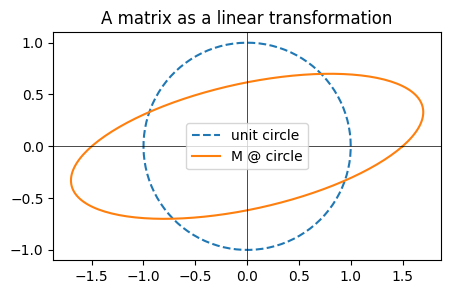

In [4]:
theta = np.linspace(0, 2 * np.pi, 200)
circle = np.vstack([np.cos(theta), np.sin(theta)])

M = np.array([[1.5, 0.8],
              [0.0, 0.7]])
transformed = M @ circle

plt.figure(figsize=(5, 5))
plt.plot(circle[0], circle[1], label="unit circle", linestyle="--")
plt.plot(transformed[0], transformed[1], label="M @ circle")
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.gca().set_aspect("equal")
plt.legend()
plt.title("A matrix as a linear transformation")
plt.show()

## 3. Linear systems and least squares

A linear system $Ax = b$ asks for coefficients that combine the columns of $A$ to produce $b$.
When there is no exact solution, we look for the closest one by minimizing the squared error:

$$ \hat{x} = \arg\min_x \|Ax - b\|_2^2 $$

Setting the derivative to zero gives the **normal equation**:

$$ A^T A \hat{x} = A^T b $$

For linear regression, $A$ is the feature matrix (often with a column of ones for the intercept) and
$b$ is the target. This is exactly what `LinearRegression` solves internally.

In [5]:
from sklearn.linear_model import LinearRegression

n = 100
x = rng.uniform(-3, 3, n)
X = np.column_stack([np.ones(n), x])
y = 4.0 + 2.5 * x + rng.normal(0, 1.0, n)

normal_solution = np.linalg.solve(X.T @ X, X.T @ y)
lstsq_solution = np.linalg.lstsq(X, y, rcond=None)[0]

model = LinearRegression().fit(x.reshape(-1, 1), y)

print("normal equation :", normal_solution)
print("np.linalg.lstsq :", lstsq_solution)
print("sklearn         :", [model.intercept_, model.coef_[0]])
print("max difference  :", np.max(np.abs(normal_solution - lstsq_solution)))

normal equation : [3.987  2.5128]
np.linalg.lstsq : [3.987  2.5128]
sklearn         : [3.9870145206180325, 2.5127715980225758]
max difference  : 1.3322676295501878e-15


Explicitly forming $A^T A$ can be numerically unstable. Production code uses QR decomposition or SVD
internally. `np.linalg.lstsq` and scikit-learn handle this for you. The normal equation is still the
clearest way to understand what least squares means.

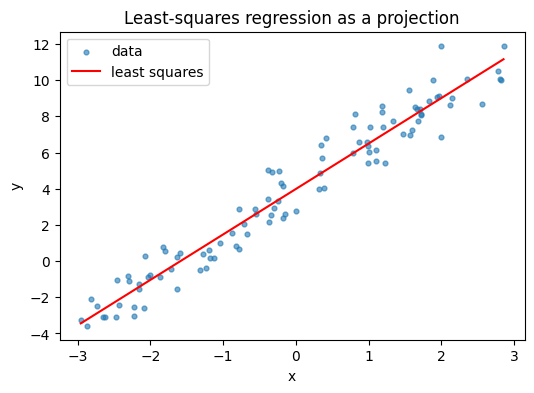

In [6]:
plt.figure(figsize=(6, 4))
plt.scatter(x, y, s=12, alpha=0.6, label="data")
xs = np.linspace(x.min(), x.max(), 100)
plt.plot(xs, normal_solution[0] + normal_solution[1] * xs, color="red", label="least squares")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Least-squares regression as a projection")
plt.show()

## 4. Rank, span, and projection

The **rank** is the number of linearly independent columns. It tells you how many dimensions the
columns actually span. If rank is less than the number of features, the design matrix is
rank-deficient and coefficients are not unique; regularization becomes important.

A **projection** of $y$ onto the column space of $A$ is the closest point to $y$ that can be written
as $Ax$. The residual is orthogonal to that space, which is the geometric reason the normal equation
works.

In [7]:
A = np.array([[1.0, 2.0, 3.0],
              [2.0, 4.0, 6.0],
              [1.0, 1.0, 1.0]])
print("rank:", np.linalg.matrix_rank(A))
print("shape:", A.shape, "-> rank is smaller than columns, so columns are dependent")

a = np.array([3.0, 4.0])
b = np.array([1.0, 0.0])
projection = (np.dot(a, b) / np.dot(b, b)) * b
print("projection of a onto b:", projection)
print("residual:", a - projection)
print("dot with b:", np.dot(a - projection, b))

rank: 2
shape: (3, 3) -> rank is smaller than columns, so columns are dependent
projection of a onto b: [3. 0.]
residual: [0. 4.]
dot with b: 0.0


## 5. Eigenvalues and eigenvectors

An eigenvector of a square matrix $C$ is a direction that the matrix only stretches:

$$ C v = \lambda v $$

The scalar $\lambda$ is the eigenvalue. For a covariance matrix, eigenvectors are the principal
directions of the data and eigenvalues measure the variance along those directions. That is PCA.

In [8]:
from sklearn.datasets import make_blobs

X_raw, _ = make_blobs(n_samples=300, centers=1, random_state=42, cluster_std=1.2)
X_raw = X_raw @ np.array([[1.0, 0.8], [0.0, 1.0]])
X_centered = X_raw - X_raw.mean(axis=0)
C = np.cov(X_centered, rowvar=False)

eigenvalues, eigenvectors = np.linalg.eigh(C)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

print("covariance matrix:\n", C)
print("eigenvalues:", eigenvalues)
print("explained variance ratio:", eigenvalues / eigenvalues.sum())
print("eigenvectors (columns):\n", eigenvectors)

covariance matrix:
 [[1.3826 1.1215]
 [1.1215 2.2591]]
eigenvalues: [3.0249 0.6167]
explained variance ratio: [0.8306 0.1694]
eigenvectors (columns):
 [[ 0.5639 -0.8258]
 [ 0.8258  0.5639]]


sklearn explained variance ratio: [0.8306 0.1694]
numpy explained variance ratio:   [0.8306 0.1694]


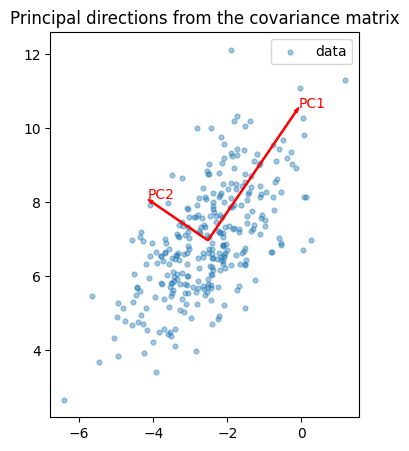

In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca.fit(X_raw)

print("sklearn explained variance ratio:", pca.explained_variance_ratio_)
print("numpy explained variance ratio:  ", eigenvalues / eigenvalues.sum())

plt.figure(figsize=(6, 5))
plt.scatter(X_raw[:, 0], X_raw[:, 1], s=12, alpha=0.4, label="data")
origin = X_raw.mean(axis=0)
for i in range(2):
    vec = eigenvectors[:, i] * np.sqrt(eigenvalues[i]) * 2.5
    plt.arrow(origin[0], origin[1], vec[0], vec[1],
              width=0.03, color="red", length_includes_head=True)
    plt.text(origin[0] + vec[0], origin[1] + vec[1], f"PC{i + 1}", color="red")
plt.gca().set_aspect("equal")
plt.legend()
plt.title("Principal directions from the covariance matrix")
plt.show()

The eigenvalues match scikit-learn's explained variance (up to rounding and sign choices). The first
principal component points along the direction of largest spread. PCA is a change of basis, not a
supervised feature-selection method: it ignores the target.

## 6. Singular value decomposition

The SVD factorizes any $n \times d$ matrix as

$$ X = U \Sigma V^T $$

where $U$ and $V$ are orthogonal and $\Sigma$ holds non-negative singular values in decreasing order.
Keeping only the largest $k$ singular values gives the best rank-$k$ approximation of $X$ in squared
error. This is the basis of PCA, latent semantic analysis, and image compression.

In [10]:
from sklearn.datasets import load_digits

digits = load_digits()
images = digits.images
X = digits.data.astype(float)
X_centered = X - X.mean(axis=0)
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

print("data shape:", X.shape)
print("singular values (first 10):", S[:10])
print("total variance captured by first 20 components:",
      (S[:20] ** 2).sum() / (S ** 2).sum())

data shape: (1797, 64)
singular values (first 10): [567.0066 542.2519 504.6306 426.1177 353.335  325.8204 305.2616 281.1603
 269.0698 257.824 ]
total variance captured by first 20 components: 0.8943031165985262


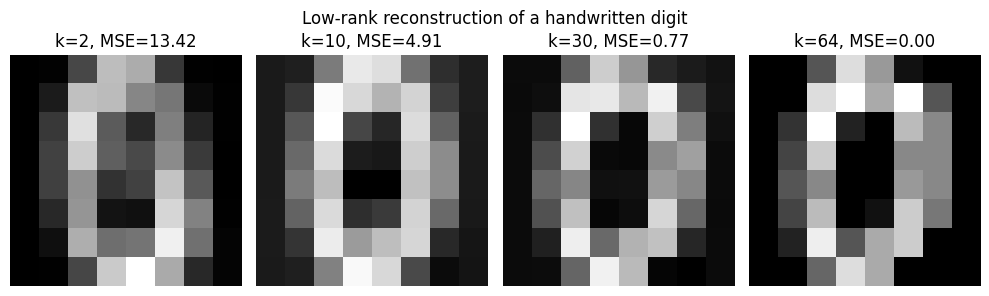

In [11]:
def reconstruct(k):
    return (U[:, :k] * S[:k]) @ Vt[:k, :] + X.mean(axis=0)

fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, k in zip(axes, [2, 10, 30, 64]):
    rec = reconstruct(k)
    mse = np.mean((X - rec) ** 2)
    ax.imshow(rec[0].reshape(8, 8), cmap="gray")
    ax.set_title(f"k={k}, MSE={mse:.2f}")
    ax.axis("off")
plt.suptitle("Low-rank reconstruction of a handwritten digit")
plt.tight_layout()
plt.show()

The reconstruction improves quickly because most of the variance lives in a few directions. This is
why PCA and truncated SVD are effective compression and denoising tools. The same idea underlies
latent semantic analysis for text.

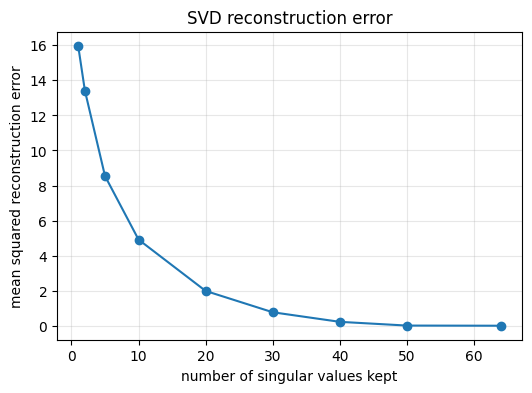

In [12]:
errors = []
ks = [1, 2, 5, 10, 20, 30, 40, 50, 64]
for k in ks:
    rec = reconstruct(k)
    errors.append(np.mean((X - rec) ** 2))

plt.figure(figsize=(6, 4))
plt.plot(ks, errors, marker="o")
plt.xlabel("number of singular values kept")
plt.ylabel("mean squared reconstruction error")
plt.title("SVD reconstruction error")
plt.grid(alpha=0.3)
plt.show()

## 7. Norms and regularization

Regularization adds a penalty on the size of the coefficients. The two most common penalties are:

- **L2 / Ridge:** $\lambda \|w\|_2^2$ shrinks coefficients smoothly.
- **L1 / Lasso:** $\lambda \|w\|_1$ can set coefficients exactly to zero.

Geometrically, the L1 ball has corners on the axes, so the optimum often lands on a sparse solution.
The L2 ball is smooth, so coefficients shrink without becoming exactly zero. This connects linear
algebra to the regularization notebook `m5.ipynb`.

In [13]:
from sklearn.linear_model import Lasso, Ridge

X_reg = X_centered
y_reg = digits.target.astype(float)

ridge = Ridge(alpha=1.0).fit(X_reg, y_reg)
lasso = Lasso(alpha=0.01, max_iter=10000).fit(X_reg, y_reg)

print("Ridge non-zero coefficients:", np.sum(np.abs(ridge.coef_) > 1e-8))
print("Lasso non-zero coefficients:", np.sum(np.abs(lasso.coef_) > 1e-8))
print("Ridge L2 norm:", np.linalg.norm(ridge.coef_))
print("Lasso L1 norm:", np.linalg.norm(lasso.coef_, ord=1))

Ridge non-zero coefficients: 61
Lasso non-zero coefficients: 51
Ridge L2 norm: 2.568457474361311
Lasso L1 norm: 3.1667760740524926


## 8. Summary

- Data is a matrix; a row is an example and a column is a feature.
- Dot products measure alignment and power linear models.
- Least squares is a projection onto the column space.
- Eigenvectors of the covariance matrix define PCA directions.
- The SVD gives optimal low-rank approximations and connects PCA, compression, and latent factor
  models.
- L1 and L2 norms explain the difference between Lasso and Ridge.

## Exercises

1. Generate a $5 \times 3$ matrix, compute its rank, and construct a dependent column.
2. Project a random 3-D vector onto the plane spanned by two independent vectors.
3. Implement PCA with `np.linalg.eigh` on the breast-cancer dataset and compare the explained
   variance ratio with scikit-learn.
4. Reconstruct a digit with 5 singular values and describe what information is lost.
5. Show experimentally that increasing the Lasso alpha reduces the number of non-zero coefficients.